# Домашняя работа №1. Проверка валидности A/B-эксперимента

**Задача:** проверить качество данных, соотношение групп 50/50, независимость
назначения от `pre_activity` и guardrail `error_flag`; принять решение о тесте.
Единица наблюдения и предполагаемой рандомизации — пользователь.

**Итог выполненного анализа:** эксперимент не валиден. Обнаружены SRM и дисбаланс
предэкспериментальной активности. Частота ошибок выше в test, но её различие в данной
выборке статистически незначимо. Правильное решение — **«Остановить тест, исправить
ошибки, перезапустить»**. Балансировка в бонусе устраняет наблюдаемый дисбаланс,
но не делает исходный эксперимент валидным.

Ноутбук выполнен; таблицы и графики сохранены. Рядом находятся `experiment_data.csv`,
`generation_metadata.json`, `generate_data.py` и `analyze_experiment.py`.
Данные синтетические, персональных данных нет.

## 1. План анализа и правила принятия решения

1. Проверить схему, пропуски, уникальность `user_id`, бинарность исходов и даты.
2. SRM: $H_0: P(test)=P(control)=0.5$, критерий хи-квадрат с одной степенью свободы.
3. Баланс: $H_0$ — одинаковое распределение `pre_activity`. Основная проверка —
   двусторонний U-тест Манна–Уитни с асимптотической поправкой на совпадающие ранги.
   Дополнительно приводятся Welch t-test для средних и стандартизованная разность
   средних (SMD). Основной тест не выбирается по меньшему p-value.
4. Guardrail: $H_0: p_{error,test}=p_{error,control}$, двусторонний точный тест Фишера;
   он подходит для редких ошибок. Покажем абсолютную разность, относительное отношение
   частот и 95% интервалы. Порог допустимого продуктового ухудшения в условии не задан.
5. Как требует задание, любое предупреждение при **номинальном $\alpha=0.05$**
   блокирует стандартный анализ первичной метрики. Дополнительно покажем поправку Holm
   для трёх основных диагностик. Это учитывает множественность, но не меняет заданное правило.
6. Бонус: точное сопоставление 1:1 по `pre_activity`, без отбора по исходам;
   сравнить оценки до/после и объяснить ограничения.

Отсутствие значимости не доказывает равенство, безопасность или корректную рандомизацию.
Проверки по одному p-value также могут давать ложные тревоги. Для реального запуска
проверки и пороги следует зафиксировать до просмотра результатов.

## 2. Окружение и вспомогательные функции

Рекомендуется Python 3.12. В Colab основные библиотеки обычно уже установлены.
Для локального запуска: `python -m pip install -r requirements.txt`.
Затем выполните ячейки последовательно. Рабочая папка должна содержать исходный CSV
и файл метаданных. Код анализа ниже самостоятельный: импортировать `.py` файлы не требуется.

In [1]:
from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline

ALPHA = 0.05
GROUPS = ["control", "test"]
COLORS = ["#376DA0", "#E18A38"]
pd.set_option("display.max_columns", 15)
pd.set_option("display.float_format", lambda x: f"{x:.6g}")
print("Python", platform.python_version(), "| NumPy", np.__version__,
      "| pandas", pd.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)

Python 3.12.5 | NumPy 2.5.5 | pandas 2.2.3 | SciPy 1.18.1 | Matplotlib 3.11.2


In [2]:
def load_data(path):
    """Останавливаем анализ при нарушении структуры, без молчаливой очистки."""
    df = pd.read_csv(path)
    required = {"user_id", "variant", "converted", "error_flag", "pre_activity", "date"}
    if not required.issubset(df.columns):
        raise ValueError(f"Нет колонок: {required - set(df.columns)}")
    if df.empty or df[list(required)].isna().any().any():
        raise ValueError("Пустая таблица или пропуски в обязательных колонках")
    if df.user_id.duplicated().any():
        raise ValueError("Повторные user_id: нарушена единица рандомизации")
    if set(df.variant) != set(GROUPS):
        raise ValueError("Ожидаются две группы: control, test")
    for column in ["converted", "error_flag"]:
        if not df[column].isin([0, 1]).all():
            raise ValueError(f"{column} должна быть бинарной")
    if not pd.api.types.is_numeric_dtype(df.pre_activity):
        raise ValueError("pre_activity должна быть числовой")
    if not np.isfinite(df.pre_activity).all() or (df.pre_activity < 0).any():
        raise ValueError("pre_activity содержит недопустимые значения")
    df["date"] = pd.to_datetime(df.date, errors="raise")
    if min(df.groupby("variant").size()) < 2:
        raise ValueError("В каждой группе нужно не менее двух пользователей")
    return df

def summary_table(df):
    result = df.groupby("variant").agg(
        n=("user_id", "size"), conversions=("converted", "sum"),
        conversion_rate=("converted", "mean"), errors=("error_flag", "sum"),
        error_rate=("error_flag", "mean"), activity_mean=("pre_activity", "mean"),
        activity_median=("pre_activity", "median"), activity_std=("pre_activity", "std"),
    ).reindex(GROUPS)
    result["share"] = result.n / len(df)
    return result

In [3]:
def wilson_interval(successes, total, alpha=ALPHA):
    """95% Wilson CI для доли: устойчивее Wald CI при редких ошибках."""
    z = stats.norm.ppf(1 - alpha / 2)
    p = successes / total
    denominator = 1 + z ** 2 / total
    center = (p + z ** 2 / (2 * total)) / denominator
    half = z / denominator * np.sqrt(p * (1 - p) / total + z ** 2 / (4 * total ** 2))
    return float(center - half), float(center + half)

def rate_difference(df, metric, compute_test=False):
    """Разность test-control и независимый Newcombe CI на основе Wilson CI."""
    s = df.groupby("variant")[metric].agg(["sum", "count", "mean"]).reindex(GROUPS)
    pc, pt = s.loc["control", "mean"], s.loc["test", "mean"]
    lc, uc = wilson_interval(s.loc["control", "sum"], s.loc["control", "count"])
    lt, ut = wilson_interval(s.loc["test", "sum"], s.loc["test", "count"])
    delta = float(pt - pc)
    lower = delta - np.sqrt((pt - lt) ** 2 + (uc - pc) ** 2)
    upper = delta + np.sqrt((ut - pt) ** 2 + (pc - lc) ** 2)
    result = {"control_rate": float(pc), "test_rate": float(pt), "difference": delta,
              "ci_low": float(lower), "ci_high": float(upper)}
    if compute_test:
        table = [[int(s.loc[g, "sum"]), int(s.loc[g, "count"] - s.loc[g, "sum"])]
                 for g in GROUPS]
        result["p_value"] = float(stats.fisher_exact(table, alternative="two-sided").pvalue)
    return result

def holm_adjust(p_values):
    """Поправка Holm для трёх заранее выбранных диагностик (дополнительно)."""
    p = np.asarray(p_values)
    order = np.argsort(p)
    adjusted = np.minimum(1, np.maximum.accumulate(p[order] * np.arange(len(p), 0, -1)))
    result = np.empty(len(p))
    result[order] = adjusted
    return result

def audit(df, design_eligible=True):
    """design_eligible=False для искусственно отобранной наблюдательной выборки."""
    summary = summary_table(df)
    counts = summary.n.to_numpy()
    srm = stats.chisquare(counts, f_exp=np.repeat(len(df) / 2, 2))
    c = df.loc[df.variant == "control", "pre_activity"]
    t = df.loc[df.variant == "test", "pre_activity"]
    # Основная проверка распределений: асимптотический U-тест с поправкой на ties.
    u = stats.mannwhitneyu(t, c, alternative="two-sided", method="asymptotic")
    welch = stats.ttest_ind(t, c, equal_var=False)
    scale = np.sqrt((t.var(ddof=1) + c.var(ddof=1)) / 2)
    smd = float((t.mean() - c.mean()) / scale) if scale > 0 else 0.0
    guard = rate_difference(df, "error_flag", compute_test=True)
    tests = pd.DataFrame({
        "check": ["SRM: chi-square, 50/50", "pre_activity: Mann–Whitney U", "error_flag: Fisher"],
        "p_value": [float(srm.pvalue), float(u.pvalue), guard["p_value"]],
    }).set_index("check")
    tests["p_holm"] = holm_adjust(tests.p_value)
    tests["warning_alpha_0.05"] = tests.p_value < ALPHA
    warnings = []
    if srm.pvalue < ALPHA:
        warnings.append("SRM обнаружен")
    if u.pvalue < ALPHA:
        warnings.append("Дисбаланс по pre_activity — возможен confounder")
    if guard["p_value"] < ALPHA:
        direction = "ухудшение" if guard["difference"] > 0 else "изменение"
        warnings.append(f"Дисбаланс guardrail error_flag — {direction}")
    result = {
        "n": len(df), "srm_chi2": float(srm.statistic), "srm_p": float(srm.pvalue),
        "activity_u": float(u.statistic), "activity_p": float(u.pvalue),
        "activity_welch_p": float(welch.pvalue), "activity_smd": smd,
        "guardrail": guard, "warnings": warnings, "checks_passed": not warnings,
        "valid": not warnings and design_eligible,
    }
    # По условию стандартный анализ конверсии разрешён только после всех проверок.
    if result["valid"]:
        result["primary_analysis"] = rate_difference(df, "converted", compute_test=True)
    return summary, tests, result

## 3. Однократная генерация и воспроизводимость

CSV получен **одним запуском исходного алгоритма**; seed и размер не подбирались
по значимости. Seed, версии библиотек и SHA-256 записаны в `generation_metadata.json`.
Повторное выполнение ноутбука загружает готовые данные и не меняет их.
В определении генератора ниже исправлена только синтаксическая опечатка `}]` → `})`.

В условии есть важные особенности:

- `np.random.exponential(...).astype(int)` даёт дискретизированное экспоненциальное
  распределение, а не логнормальное и не строго непрерывную ковариату.
- Первое назначение 40/60 перезаписывается `variant2`. Оно **не является итоговым
  соотношением**; предыдущий вызов RNG сохранён для соответствия алгоритму.
- Итоговая вероятность теста $0.4+0.3X/X_{max}$ одновременно создаёт зависимость
  от активности и отклонение от запланированных 50/50. Это не сумма двух
  независимых механизмов назначения. Проверять нужно фактический CSV.
- Ожидаемая доля test, условно на реализованных активностях, равна
  $0.4+0.3\bar X/X_{max}$; она не обязана составлять ни 40%, ни 60%.

In [4]:
def generate_once(directory=Path.cwd()):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    csv_path = directory / "experiment_data.csv"
    if csv_path.exists():
        raise FileExistsError("CSV уже существует: повторная генерация запрещена.")

    # Один случайный seed, затем строго исходная последовательность вызовов RNG.
    my_seed = int(np.random.randint(5000000, size=1)[0])
    np.random.seed(my_seed)
    n_users = int(np.random.randint(1000, 10000, size=1)[0])
    pre_activity = np.random.exponential(scale=10, size=n_users).astype(int)
    variant = np.random.choice(["control", "test"], size=n_users, p=[0.4, 0.6])
    prob_test = 0.4 + 0.3 * (pre_activity / pre_activity.max())
    variant2 = np.where(np.random.random(n_users) < prob_test, "test", "control")
    # Сохраняем перезапись из задания, включая предыдущий расход случайных чисел.
    variant = variant2
    error_flag = np.zeros(n_users)
    error_flag[variant == "control"] = np.random.binomial(
        1, 0.01, sum(variant == "control")
    )
    error_flag[variant == "test"] = np.random.binomial(
        1, 0.02, sum(variant == "test")
    )
    conversion_prob = 0.05 + 0.01 * (pre_activity / pre_activity.max())
    converted = np.random.binomial(1, conversion_prob, n_users)
    start_date = pd.Timestamp("2026-05-01")
    dates = [start_date + pd.Timedelta(days=np.random.randint(0, 14))
             for _ in range(n_users)]
    # Единственное исправление исходника — синтаксическая опечатка `}]` -> `})`.
    df = pd.DataFrame({
        "user_id": range(n_users), "variant": variant, "converted": converted,
        "error_flag": error_flag, "pre_activity": pre_activity, "date": dates,
    })
    df.to_csv(csv_path, index=False)
    metadata = {
        "MY_SEED": my_seed, "n_users": n_users,
        "csv_sha256": hashlib.sha256(csv_path.read_bytes()).hexdigest(),
        "generation_runs": 1,
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__,
        "note": "Исходные параметры сохранены. Seed не подбирался по результатам тестов.",
    }
    (directory / "generation_metadata.json").write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
    )
    print(json.dumps(metadata, ensure_ascii=False, indent=2))
    return df, metadata

# Уже выполнено один раз при подготовке CSV. Не перезапускаем:
# df, metadata = generate_once(Path.cwd())

In [5]:
DATA_DIR = Path.cwd()
csv_path = DATA_DIR / "experiment_data.csv"
metadata_path = DATA_DIR / "generation_metadata.json"
if not csv_path.exists() or not metadata_path.exists():
    raise FileNotFoundError("Скачайте experiment_data.csv и generation_metadata.json из репозитория в рабочую папку.")
metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
actual_hash = hashlib.sha256(csv_path.read_bytes()).hexdigest()
if actual_hash != metadata["csv_sha256"]:
    raise ValueError("SHA-256 не совпадает: файл данных изменён")
df = load_data(csv_path)
assert len(df) == metadata["n_users"]
display(pd.Series(metadata, name="Значение").to_frame())
print("SHA-256 проверен. Данные не перегенерировались.")

,Значение
MY_SEED,4279692
n_users,3572
csv_sha256,25c8b8cd30b44bc2e0a08b0b9814570263670b52491bc2...
generation_runs,1
python,3.12.5
numpy,2.5.5
pandas,2.2.3
note,Исходные параметры сохранены. Seed не подбирал...


SHA-256 проверен. Данные не перегенерировались.


## 4. Проверка качества и базовые показатели

Каждый пользователь должен присутствовать один раз. Проверяем все строки без
удаления неудобных наблюдений. `error_flag` записан исходным генератором как
`float`, но содержит только 0.0/1.0, поэтому семантически остаётся бинарным.
Даты проверяем на диапазон и полноту; отдельные временные гипотезы не тестируем.

In [6]:
quality = pd.Series({
    "Строк": len(df), "Столбцов": df.shape[1],
    "Пропусков": int(df.isna().sum().sum()),
    "Повторных user_id": int(df.user_id.duplicated().sum()),
    "Полных дубликатов": int(df.duplicated().sum()),
    "Уникальных дат": df.date.nunique(),
    "Начало": str(df.date.min().date()), "Конец": str(df.date.max().date()),
})
assert df.date.between("2026-05-01", "2026-05-14").all()
assert set(df.user_id) == set(range(len(df)))
display(quality.to_frame("Результат"))
display(df.head())
summary, tests, result = audit(df)
display(summary)
print("Ожидаемое число в каждой группе:", len(df) / 2)
print("Ожидаемая по генератору доля test при данных активностях:",
      f"{0.4 + 0.3 * df.pre_activity.mean() / df.pre_activity.max():.2%}")

,Результат
Строк,3572
Столбцов,6
Пропусков,0
Повторных user_id,0
Полных дубликатов,0
Уникальных дат,14
Начало,2026-05-01
Конец,2026-05-14


,user_id,variant,converted,error_flag,pre_activity,date
0,0,control,0,0,2,2026-05-09
1,1,control,0,0,44,2026-05-08
2,2,control,0,0,0,2026-05-10
3,3,control,0,0,1,2026-05-03
4,4,test,0,0,0,2026-05-05


,n,conversions,conversion_rate,errors,error_rate,activity_mean,activity_median,activity_std,share
variant,,,,,,,,,
control,2067,106,0.0512821,27,0.0130624,8.67296,6,9.25687,0.578667
test,1505,73,0.048505,30,0.0199336,10.1834,7,10.9041,0.421333


Ожидаемое число в каждой группе: 1786.0
Ожидаемая по генератору доля test при данных активностях: 43.04%


## 5. Проверка SRM

Сравниваем численности с $N/2$, а не с фактическими или подсмотренными
вероятностями генератора. В хи-квадрат тесте ожидаемые частоты велики.
Значимый SRM означает несоответствие запланированному дизайну; сам по себе
дисбаланс размеров ещё не доказывает смещение конверсии.

In [7]:
print(f"χ²(1) = {result['srm_chi2']:.6f}, p-value = {result['srm_p']:.6g}")
print("SRM обнаружен" if result["srm_p"] < ALPHA else "SRM статистически не обнаружен")

χ²(1) = 88.422172, p-value = 5.28748e-21
SRM обнаружен


## 6. Баланс предэкспериментальной активности

Экспоненциальная форма, правый хвост и многочисленные совпадающие целые значения
мотивируют U-тест. Его нулевая гипотеза относится к распределениям;
это не универсальный тест равенства средних или медиан. Welch t-test проверяет
средние и приведён отдельно как проверка устойчивости. SMD оценивает размер
дисбаланса: $(\bar X_t-\bar X_c)/\sqrt{(s_t^2+s_c^2)/2}$.

Активность измерена до эксперимента и влияет на вероятность конверсии. При её
связи с назначением возникает потенциальный confounder. Один баланс-тест
не устанавливает причину, но здесь причина также известна из генератора.

In [8]:
display(df.groupby("variant").pre_activity.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).reindex(GROUPS))
print("Асимметрия pre_activity:", round(df.pre_activity.skew(), 3))
print(f"Mann–Whitney U = {result['activity_u']:.1f}; p = {result['activity_p']:.6g}")
print(f"Welch t-test p = {result['activity_welch_p']:.6g}; SMD = {result['activity_smd']:.4f}")
print("Дисбаланс по pre_activity — возможен confounder"
      if result["activity_p"] < ALPHA else "Значимого дисбаланса pre_activity не обнаружено")

,count,mean,std,min,25%,50%,75%,95%,max
variant,,,,,,,,,
control,2067,8.67296,9.25687,0,2,6,12,27,92
test,1505,10.1834,10.9041,0,2,7,15,32,91


Асимметрия pre_activity: 2.15
Mann–Whitney U = 1658931.0; p = 0.000655761
Welch t-test p = 1.39583e-05; SMD = 0.1493
Дисбаланс по pre_activity — возможен confounder


## 7. Guardrail: ошибки загрузки страницы

Для отдельных частот используются 95% Wilson CI, для разности test−control —
95% Newcombe CI на их основе. Все разности ниже выражены в **процентных пунктах**,
а не в процентах относительного роста. Тест Фишера двусторонний.

In [9]:
guard = result["guardrail"]
rows = []
for group in GROUPS:
    row = summary.loc[group]
    lo, hi = wilson_interval(row.errors, row.n)
    rows.append({"Группа": group, "Ошибок": int(row.errors), "Пользователей": int(row.n),
                 "Частота, %": 100 * row.error_rate,
                 "95% CI нижний, %": 100 * lo, "95% CI верхний, %": 100 * hi})
display(pd.DataFrame(rows).set_index("Группа"))
print(f"Разность test-control: {100 * guard['difference']:.3f} п.п.; "
      f"95% CI [{100 * guard['ci_low']:.3f}; {100 * guard['ci_high']:.3f}] п.п.")
ratio = guard["test_rate"] / guard["control_rate"] if guard["control_rate"] else np.nan
print(f"Отношение наблюдаемых частот test/control: {ratio:.3f}; Fisher p = {guard['p_value']:.6g}")
if guard["p_value"] < ALPHA:
    print("Значимый дисбаланс guardrail; направление test-control:", np.sign(guard["difference"]))
else:
    print("Различие статистически незначимо. Это не доказывает отсутствие ухудшения.")

,Ошибок,Пользователей,"Частота, %","95% CI нижний, %","95% CI верхний, %"
Группа,,,,,
control,27,2067,1.30624,0.899272,1.89387
test,30,1505,1.99336,1.39981,2.83135


Разность test-control: 0.687 п.п.; 95% CI [-0.148; 1.619] п.п.
Отношение наблюдаемых частот test/control: 1.526; Fisher p = 0.136194
Различие статистически незначимо. Это не доказывает отсутствие ухудшения.


**Интерпретация данной реализации.** Ошибки: 27/2067 (1,306%) в control и
30/1505 (1,993%) в test. Наблюдаемое отношение частот — около 1,53,
а не ровно 2. Разность +0,687 п.п., 95% CI [−0,148; +1,619] п.п.;
`p=0,136`. Поэтому по CSV при уровне 0,05 третье нарушение **не подтверждено
статистически**, хотя направление соответствует ухудшению.

В исходном коде вероятности действительно равны 0,01 и 0,02: искусственная
проблема guardrail присутствует в механизме генерации. Случайная выборка не обязана
обнаружить каждый заложенный эффект. Редкие ошибки и ограниченный объём дают
неопределённость. Перегенерировать данные ради значимого p-value было бы ошибкой.
Для вывода об отсутствии практически опасного ухудшения понадобились бы заранее
заданный порог неухудшения и достаточная мощность; здесь их нет.

## 8. Визуализации и итог трёх диагностик

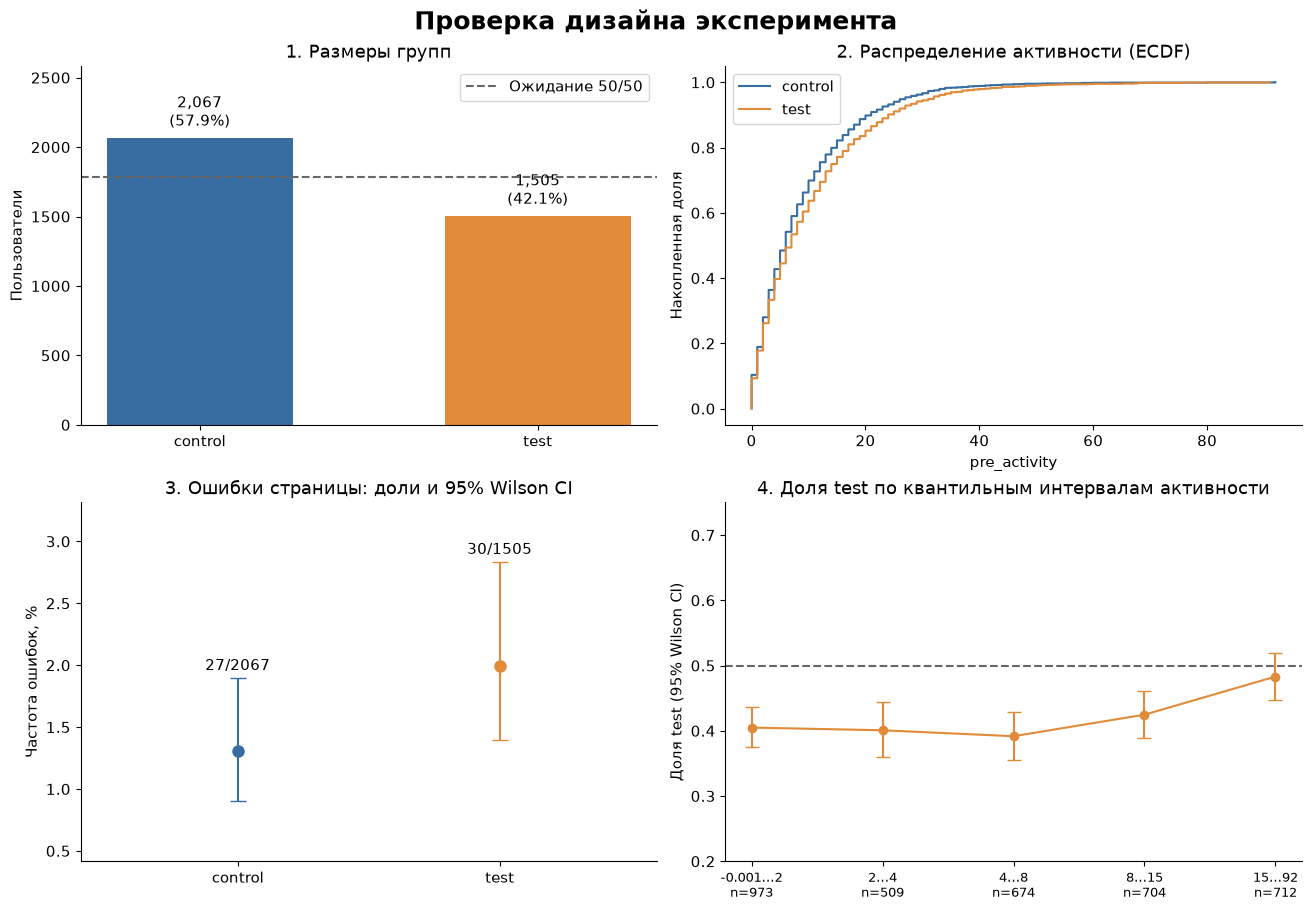

In [10]:
def plot_diagnostics(df):
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                         "axes.spines.top": False, "axes.spines.right": False})
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
    summary = summary_table(df)
    ax = axes[0, 0]
    bars = ax.bar(GROUPS, summary.n, color=COLORS, width=0.55)
    ax.axhline(len(df) / 2, linestyle="--", color="#666666", label="Ожидание 50/50")
    ax.bar_label(bars, labels=[f"{n:,}\n({n / len(df):.1%})" for n in summary.n], padding=5)
    ax.set(title="1. Размеры групп", ylabel="Пользователи", ylim=(0, summary.n.max() * 1.25))
    ax.legend(loc="upper right")
    ax = axes[0, 1]
    for group, color in zip(GROUPS, COLORS):
        x = np.sort(df.loc[df.variant == group, "pre_activity"].to_numpy())
        ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", label=group, color=color)
    ax.set(title="2. Распределение активности (ECDF)", xlabel="pre_activity", ylabel="Накопленная доля")
    ax.legend()
    ax = axes[1, 0]
    for position, (group, color) in enumerate(zip(GROUPS, COLORS)):
        row = summary.loc[group]
        lo, hi = wilson_interval(row.errors, row.n)
        ax.errorbar(position, 100 * row.error_rate,
                    yerr=[[100 * (row.error_rate - lo)], [100 * (hi - row.error_rate)]],
                    fmt="o", capsize=6, markersize=8, color=color)
        ax.annotate(f"{int(row.errors)}/{int(row.n)}", (position, 100 * hi),
                    xytext=(0, 6), textcoords="offset points", ha="center")
    ax.set(xticks=[0, 1], xticklabels=GROUPS, xlim=(-0.6, 1.6),
           title="3. Ошибки страницы: доли и 95% Wilson CI", ylabel="Частота ошибок, %")
    ax.margins(y=0.25)
    ax = axes[1, 1]
    bins = pd.qcut(df.pre_activity, q=5, duplicates="drop")
    trend = df.assign(activity_bin=bins, in_test=(df.variant == "test").astype(int)).groupby(
        "activity_bin", observed=True).agg(n=("in_test", "size"), test=("in_test", "sum"))
    p = trend.test / trend.n
    ci = np.array([wilson_interval(k, n) for k, n in zip(trend.test, trend.n)])
    ax.errorbar(np.arange(len(trend)), p, yerr=[p - ci[:, 0], ci[:, 1] - p],
                fmt="o-", color=COLORS[1], capsize=5)
    ax.axhline(0.5, linestyle="--", color="#666666", label="Независимое назначение 50/50")
    labels = [f"{interval.left:g}…{interval.right:g}\nn={n}" for interval, n in zip(trend.index, trend.n)]
    ax.set(xticks=np.arange(len(trend)), xticklabels=labels, ylim=(0.2, 0.75),
           title="4. Доля test по квантильным интервалам активности", ylabel="Доля test (95% Wilson CI)")
    ax.tick_params(axis="x", labelsize=9)
    fig.suptitle("Проверка дизайна эксперимента", fontsize=18, fontweight="bold")
    return fig

fig = plot_diagnostics(df)
plt.show()

In [11]:
display(tests)
print("Предупреждения:")
for warning in result["warnings"]:
    print("•", warning)
if not result["valid"]:
    print("Эксперимент не валиден.")
    print("Остановить тест, исправить ошибки, перезапустить")
    print("Стандартный тест первичной метрики не выполняется: нарушен дизайн.")
else:
    primary = result["primary_analysis"]
    print("Диагностики пройдены. Fisher p для конверсии:", primary["p_value"])
    print("Различие значимо" if primary["p_value"] < ALPHA else "Значимых различий не обнаружено")

,p_value,p_holm,warning_alpha_0.05
check,,,
"SRM: chi-square, 50/50",5.28748e-21,1.58624e-20,True
pre_activity: Mann–Whitney U,0.000655761,0.00131152,True
error_flag: Fisher,0.136194,0.136194,False


Предупреждения:
• SRM обнаружен
• Дисбаланс по pre_activity — возможен confounder
Эксперимент не валиден.
Остановить тест, исправить ошибки, перезапустить
Стандартный тест первичной метрики не выполняется: нарушен дизайн.


После поправки Holm SRM и дисбаланс активности также остаются значимыми.
Исходные конверсии — 5,128% и 4,850% — остаются описательными характеристиками,
на их основании нельзя принимать решение о причинном эффекте варианта.

### Уточнение фразы «истинного эффекта нет»

Генератор задаёт $P(Y=1\mid X,V)=0.05+0.01X/X_{max}$: при одинаковой активности
вариант не влияет на конверсию, условный причинный эффект равен нулю.
Но при разных распределениях активности **ожидаемые маргинальные конверсии
групп могут слегка различаться**. Это композиционное смещение, а не эффект варианта.
Ошибки страницы в данном генераторе также не входят в формулу конверсии:
не следует придумывать несуществующую причинную связь `error_flag → converted`.

In [12]:
expected_by_group = (0.05 + 0.01 * df.pre_activity / df.pre_activity.max()).groupby(df.variant).mean().reindex(GROUPS)
display((100 * expected_by_group).to_frame("Ожидаемая по формуле конверсия, %"))
expected_bias = expected_by_group["test"] - expected_by_group["control"]
print(f"Композиционная разность test-control: {100 * expected_bias:.4f} п.п.")
print("Это расчёт по известной формуле генератора, а не оценка из наблюдаемых converted.")

,"Ожидаемая по формуле конверсия, %"
variant,
control,5.09427
test,5.11069


Композиционная разность test-control: 0.0164 п.п.
Это расчёт по известной формуле генератора, а не оценка из наблюдаемых converted.


## 9. Бонус: точное сопоставление по активности

Для каждого целого значения `pre_activity` берём одинаковое число пользователей
из control и test: минимум из двух численностей в данном слое. Внутри слоя
пользователи выбираются случайно, без использования `converted` или `error_flag`.
Seed сопоставления фиксирован заранее и отличается от seed генерации.

Это корректирует наблюдаемый дисбаланс по единственной ковариате на общем
покрытии. Платой становятся потеря данных и изменение целевой популяции.
Не удаляем пользователей с ошибками или неудобными исходами: такой отбор после
воздействия может создать дополнительное смещение. Исходный CSV сохраняется.

In [13]:
def exact_match(df, seed=20261122):
    """1:1 отбор в каждом точном значении pre_activity, без использования исходов.

    Сохранение исходных user_id позволяет проверить отсутствие повторов/подмены.
    Это балансировка наблюдаемой ковариаты, а не восстановление рандомизации.
    """
    rng = np.random.default_rng(seed)
    selected = []
    for _, stratum in df.groupby("pre_activity", sort=True):
        ids = {g: stratum.index[stratum.variant == g].to_numpy() for g in GROUPS}
        k = min(len(ids[g]) for g in GROUPS)
        if k:
            for group in GROUPS:
                selected.extend(rng.choice(ids[group], size=k, replace=False))
    if not selected:
        raise ValueError("Нет общего покрытия по pre_activity")
    return df.loc[selected].copy().sort_values("user_id").reset_index(drop=True)

matched = exact_match(df)
matched_summary, matched_tests, matched_result = audit(matched, design_eligible=False)

In [14]:
balance = pd.crosstab(matched.pre_activity, matched.variant).reindex(columns=GROUPS, fill_value=0)
assert (balance.control == balance.test).all()
assert matched.user_id.is_unique
assert set(matched.user_id).issubset(set(df.user_id))
assert not matched_result["valid"]  # Отбор не восстанавливает исходную рандомизацию.
retention = pd.concat([summary.n.rename("До"), matched_summary.n.rename("После")], axis=1)
retention["Сохранено, %"] = 100 * retention["После"] / retention["До"]
display(retention)
display(matched_summary)
display(matched_tests)
print(f"Всего осталось {len(matched)} из {len(df)} ({len(matched) / len(df):.2%}).")
print(f"SMD после сопоставления: {matched_result['activity_smd']:.4f}")
print("Описательные диагностики после отбора пройдены:", matched_result["checks_passed"])
print("Валидность исходного эксперимента восстановлена:", matched_result["valid"])

,До,После,"Сохранено, %"
variant,,,
control,2067,1456,70.4403
test,1505,1456,96.7442


,n,conversions,conversion_rate,errors,error_rate,activity_mean,activity_median,activity_std,share
variant,,,,,,,,,
control,1456,83,0.0570055,18,0.0123626,9.20124,6,9.17969,0.5
test,1456,70,0.0480769,29,0.0199176,9.20124,6,9.17969,0.5


,p_value,p_holm,warning_alpha_0.05
check,,,
"SRM: chi-square, 50/50",1,1,False
pre_activity: Mann–Whitney U,1,1,False
error_flag: Fisher,0.140621,0.421864,False


Всего осталось 2912 из 3572 (81.52%).
SMD после сопоставления: 0.0000
Описательные диагностики после отбора пройдены: True
Валидность исходного эксперимента восстановлена: False


В выборке после сопоставления 1456 пользователей в каждой группе, всего 2912
(сохранено 81,52%). Распределения активности совпадают **по построению**,
поэтому SMD=0 и p-value баланс-тестов равны 1. Эти p-value не доказывают
исправность первоначального назначения. SRM проверяется прежде всего по полному
потоку назначения; искусственное равенство размеров после отбора его причину не устраняет.

После отбора частоты ошибок — 1,236% и 1,992%; разность +0,755 п.п.,
Fisher `p≈0,141`. Следовательно, наблюдаемое ухудшение guardrail сохраняет
то же направление. Даже отсутствие всех трёх формальных предупреждений в
отобранных данных не оправдывает признание исходного теста валидным.

In [15]:
comparison = []
for label, data in [("До сопоставления", df), ("После сопоставления", matched)]:
    s = summary_table(data)
    # Только описательные оценки; p-value конверсии не интерпретируем.
    r = rate_difference(data, "converted")
    comparison.append({"Выборка": label, "n": len(data),
                       "Конверсия control, %": 100 * s.loc["control", "conversion_rate"],
                       "Конверсия test, %": 100 * s.loc["test", "conversion_rate"],
                       "Разность, п.п.": 100 * r["difference"],
                       "95% CI нижний, п.п.": 100 * r["ci_low"],
                       "95% CI верхний, п.п.": 100 * r["ci_high"]})
display(pd.DataFrame(comparison).set_index("Выборка"))

,n,"Конверсия control, %","Конверсия test, %","Разность, п.п.","95% CI нижний, п.п.","95% CI верхний, п.п."
Выборка,,,,,,
До сопоставления,3572,5.12821,4.8505,-0.277707,-1.70107,1.20878
После сопоставления,2912,5.70055,4.80769,-0.892857,-2.53309,0.737544


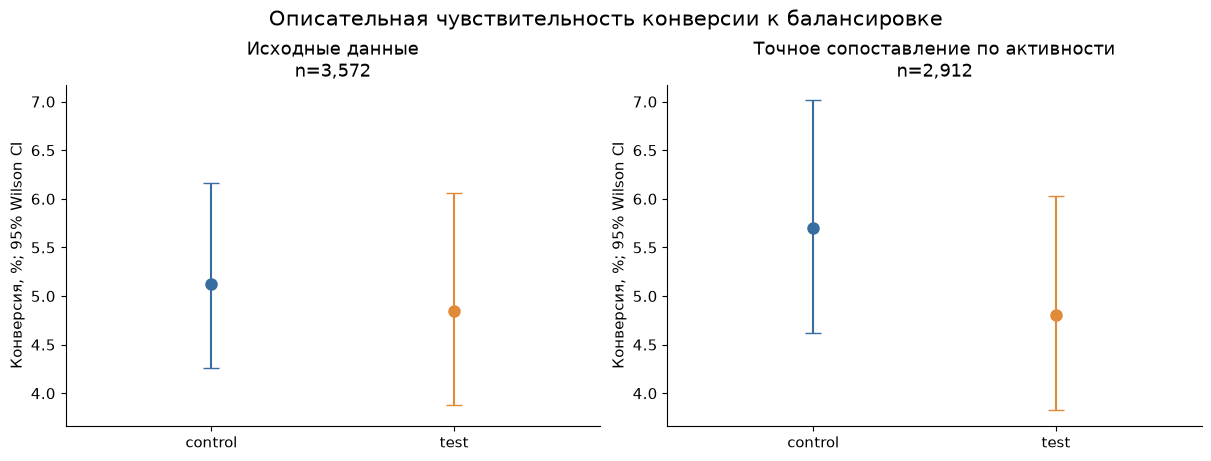

In [16]:
def plot_correction(df, matched):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    for data, title, ax in zip([df, matched], ["Исходные данные", "Точное сопоставление по активности"], axes):
        summary = summary_table(data)
        for pos, (group, color) in enumerate(zip(GROUPS, COLORS)):
            row = summary.loc[group]
            lo, hi = wilson_interval(row.conversions, row.n)
            ax.errorbar(pos, row.conversion_rate * 100,
                        yerr=[[100 * (row.conversion_rate - lo)], [100 * (hi - row.conversion_rate)]],
                        fmt="o", markersize=8, capsize=6, color=color)
        ax.set(xticks=[0, 1], xticklabels=GROUPS, xlim=(-0.6, 1.6),
               title=f"{title}\nn={len(data):,}", ylabel="Конверсия, %; 95% Wilson CI")
    limits = [ax.get_ylim() for ax in axes]
    for ax in axes:
        ax.set_ylim(min(x[0] for x in limits), max(x[1] for x in limits))
    fig.suptitle("Описательная чувствительность конверсии к балансировке", fontsize=15)
    return fig

fig = plot_correction(df, matched)
plt.show()

Разность конверсий изменилась с −0,278 до −0,893 п.п. Она не обязана
приближаться к нулю при балансировке: исходы случайны, часть пользователей
удаляется, а воздействие активности на вероятность конверсии в генераторе слабое.
Оба описательных интервала включают ноль; это не доказательство нулевого эффекта.
После сопоставления интервалы Newcombe являются приближённым описанием
неопределённости, а не полноценным условным анализом сопоставленного дизайна.

Для причинной интерпретации скорректированной наблюдательной оценки нужны
условная независимость назначения и исходов при фиксированной активности,
общее покрытие и отсутствие неизмеренных confounder. Известный генератор
поддерживает эти предпосылки для данной учебной модели, но реальные данные
одним баланс-тестом их не подтверждают. Целевая популяция после отбора другая.

Альтернатива для исследования чувствительности — IPW или регрессионная
стандартизация по `pre_activity` с проверкой перекрытия вероятностей назначения
и эффективного размера выборки. Ни один из этих методов не исправляет сам
механизм назначения или ошибки загрузки страницы.

## 10. Что исправить перед повторным запуском

1. **Назначение и SRM.** Сделать независимое от активности назначение с вероятностью
   0,5 на уровне пользователя, например стабильным хешем `user_id` и salt эксперимента.
   Исключить последующую перезапись группы. Проверить sticky assignment,
   повторные назначения, eligibility, полноту логов и потери событий по группам.
   Мониторить SRM по журналу всех назначенных пользователей, а не только дошедших до страницы.
2. **Баланс активности.** Проверить независимость назначения от предэкспериментальных
   признаков. При необходимости заранее применять стратифицированную рандомизацию
   по активности; при анализе учитывать страты. Зафиксировать метрику до воздействия.
3. **Guardrail.** Разобрать ошибки страницы по типам, версиям, браузерам и устройствам,
   проверить симметричность логирования и исправить техническую причину роста ошибок.
   В учебном генераторе различие специально внесено в вероятности 0,01/0,02;
   механически удалять ошибочные строки из реального эксперимента нельзя.
4. **Повторный запуск.** Сначала A/A и проверка логирования, затем новый эксперимент
   на новом корректном назначении. До старта задать длительность, MDE конверсии,
   порог guardrail, мощность и правила остановки. При частых промежуточных проверках
   применять заранее выбранную последовательную процедуру.

**Вывод:** данные структурно корректны, но дизайн нарушен. SRM и активность
статистически подтверждены; guardrail ухудшен в генераторе, однако в полученном CSV
доказательств различия на уровне 0,05 недостаточно. Подбор seed не выполнялся.
Сопоставление демонстрирует коррекцию одной наблюдаемой проблемы и её ограничения.
Итоговое решение не меняется: **остановить тест, исправить ошибки, перезапустить**.

## 11. Воспроизведение и сдача

Данные и ноутбук следует размещать вместе в репозитории. В образовательную
платформу сдаётся **ссылка на выполненный ноутбук**, а не сами файлы.

Локальный запуск анализа без ноутбука:

```bash
python -m pip install -r requirements.txt
python analyze_experiment.py --data experiment_data.csv
```

Графики и машиночитаемые результаты скрипт сохраняет в `analysis_outputs/`.
Для повторного просмотра результатов генератор запускать не нужно.
При запуске `generate_data.py` в папке с существующим CSV он завершится
с `FileExistsError`, чтобы защитить уникальные данные от перезаписи.